# A/B Test for SaaS Onboarding

Учебный продуктовый проект на синтетических данных.

## Контекст

У SaaS-сервиса аналитики для продавцов маркетплейсов есть проблема: после регистрации часть пользователей не подключает магазин и не доходит до первого отчёта.

Проверяем новый onboarding:

- **A — control:** после регистрации пользователь самостоятельно ищет раздел подключения магазина;
- **B — test:** пошаговый wizard помогает подключить магазин, дождаться загрузки данных и открыть первый отчёт.

## Гипотеза

Новый onboarding повысит **Activation Rate** без ухудшения качества привлечённых пользователей.

### Primary metric

**Activation Rate** = доля зарегистрированных пользователей, которые подключили магазин и открыли первый отчёт.

### Secondary metrics

- Store Connection Rate
- Data Load Rate
- D7 Retention среди активированных
- Median Time to Connect

### Guardrail

- Support Ticket Rate в первые 7 дней


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency
from statsmodels.stats.proportion import proportions_ztest, proportion_confint

pd.set_option('display.max_columns', 50)

df_raw = pd.read_csv('saas_onboarding_ab_raw.csv', parse_dates=['signup_date'])
df_raw.head()


,user_id,group,signup_date,device,acquisition_channel,connected_store,data_loaded,first_report_viewed,d7_retained,support_ticket,time_to_connect_min
0,U00001,B,2026-08-27,mobile,organic,1,1,1,0,0,7.64
1,U00002,A,2026-08-20,mobile,paid_search,1,1,0,0,0,16.17
2,U00003,A,2026-08-12,mobile,organic,0,0,0,0,0,NaN
3,U00004,A,2026-08-13,mobile,paid_search,1,1,1,1,0,16.21
4,U00005,A,2026-08-20,mobile,organic,0,0,0,0,0,NaN


## 1. Проверка качества данных

In [2]:
print('Rows:', len(df_raw))
print('Unique users:', df_raw['user_id'].nunique())
print('Duplicates by user_id:', df_raw['user_id'].duplicated().sum())
print('Missing values:')
display(df_raw.isna().sum())


Rows: 2404
Unique users: 2400
Duplicates by user_id: 4
Missing values:


user_id                  0
group                    0
signup_date              0
device                   0
acquisition_channel      2
connected_store          0
data_loaded              0
first_report_viewed      0
d7_retained              0
support_ticket           0
time_to_connect_min    820
dtype: int64

In [3]:
# Удаляем повторные строки одного пользователя.
df = df_raw.drop_duplicates(subset='user_id', keep='first').copy()

# Пропущенный канал не мешает primary metric, поэтому сохраняем пользователя.
df['acquisition_channel'] = df['acquisition_channel'].fillna('unknown')

# Отрицательное время подключения физически невозможно.
# Пользователя не удаляем, а только исключаем некорректное значение из анализа времени.
df.loc[df['time_to_connect_min'] < 0, 'time_to_connect_min'] = np.nan

# Activation = магазин подключен и пользователь открыл первый отчёт.
df['activated'] = (
    (df['connected_store'] == 1) &
    (df['first_report_viewed'] == 1)
).astype(int)

print('Rows after cleaning:', len(df))
print(df['group'].value_counts())


Rows after cleaning: 2400
group
B    1200
A    1200
Name: count, dtype: int64


После очистки остаётся 2400 уникальных пользователей: по 1200 в каждой группе.

Важно: пропущенный acquisition channel не является причиной удалять пользователя из A/B-теста, потому что primary metric от этого поля не зависит.

## 2. Проверка баланса групп

In [4]:
device_table = pd.crosstab(df['device'], df['group'])
channel_table = pd.crosstab(df['acquisition_channel'], df['group'])

display(device_table)
display(channel_table)

device_p = chi2_contingency(device_table)[1]
channel_p = chi2_contingency(channel_table)[1]

print(f'Device balance p-value: {device_p:.3f}')
print(f'Channel balance p-value: {channel_p:.3f}')


group,A,B
device,,
desktop,520,520
mobile,680,680


group,A,B
acquisition_channel,,
content,306,295
organic,356,361
paid_search,375,359
referral,161,185
unknown,2,0


Device balance p-value: 1.000
Channel balance p-value: 0.373


При уровне значимости 0.05 нет оснований считать распределения по устройствам и каналам различными между A и B. Это не доказывает идеальную рандомизацию, но явного дисбаланса по доступным признакам не видно.

## 3. Воронка onboarding

In [5]:
funnel = df.groupby('group').agg(
    users=('user_id', 'count'),
    connected_store=('connected_store', 'mean'),
    data_loaded=('data_loaded', 'mean'),
    activated=('activated', 'mean')
)

funnel_display = funnel.copy()

funnel_display[
    ["connected_store", "data_loaded", "activated"]
] *= 100

display(funnel_display.round(1))


,users,connected_store,data_loaded,activated
group,,,,
A,1200,61.7,57.2,46.8
B,1200,70.2,66.2,57.1


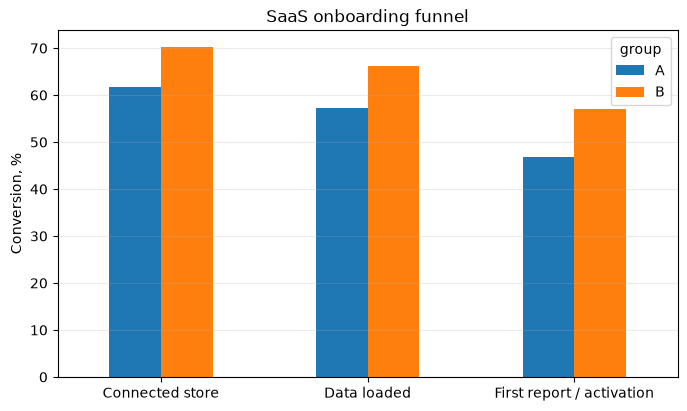

In [6]:
plot_df = funnel[['connected_store', 'data_loaded', 'activated']].T * 100
plot_df.index = ['Connected store', 'Data loaded', 'First report / activation']

ax = plot_df.plot(kind='bar', figsize=(8, 4.5))
ax.set_ylabel('Conversion, %')
ax.set_title('SaaS onboarding funnel')
ax.set_xlabel('')
ax.grid(axis='y', alpha=0.25)
plt.xticks(rotation=0)
plt.show()


## 4. Primary metric: Activation Rate

In [7]:
a = df[df['group'] == 'A']
b = df[df['group'] == 'B']

count = np.array([a['activated'].sum(), b['activated'].sum()])
nobs = np.array([len(a), len(b)])

cr_a, cr_b = count / nobs
absolute_uplift = cr_b - cr_a
relative_uplift = cr_b / cr_a - 1

print(f'A activation: {cr_a:.2%} ({count[0]}/{nobs[0]})')
print(f'B activation: {cr_b:.2%} ({count[1]}/{nobs[1]})')
print(f'Absolute uplift: {absolute_uplift:.2%}')
print(f'Relative uplift: {relative_uplift:.2%}')


A activation: 46.83% (562/1200)
B activation: 57.08% (685/1200)
Absolute uplift: 10.25%
Relative uplift: 21.89%


Читаем по-человечески: новая версия увеличила долю активированных пользователей. Но одной разницы процентов недостаточно — проверяем, насколько она совместима со случайным шумом.

In [8]:
z_stat, p_value = proportions_ztest(count, nobs)

# 95% CI для разницы двух независимых долей (normal approximation)
se = np.sqrt(
    cr_a * (1 - cr_a) / nobs[0] +
    cr_b * (1 - cr_b) / nobs[1]
)
diff_ci = (
    absolute_uplift - 1.96 * se,
    absolute_uplift + 1.96 * se
)

ci_a = proportion_confint(count[0], nobs[0], alpha=0.05, method='wilson')
ci_b = proportion_confint(count[1], nobs[1], alpha=0.05, method='wilson')

print(f'z = {z_stat:.3f}')
print(f'p-value = {p_value:.8f}')
print(f'95% CI A: [{ci_a[0]:.2%}; {ci_a[1]:.2%}]')
print(f'95% CI B: [{ci_b[0]:.2%}; {ci_b[1]:.2%}]')
print(f'95% CI effect: [{diff_ci[0]:.2%}; {diff_ci[1]:.2%}]')


z = -5.025
p-value = 0.00000050
95% CI A: [44.02%; 49.66%]
95% CI B: [54.26%; 59.86%]
95% CI effect: [6.27%; 14.23%]


### Интерпретация

При $\alpha=0.05$ p-value значительно меньше 0.05, поэтому нулевая гипотеза о равенстве Activation Rate отвергается.

Доверительный интервал эффекта полностью выше нуля, поэтому наблюдаемый прирост выглядит не только статистически значимым, но и продуктово заметным.

## 5. Secondary metric: D7 Retention

In [9]:
activated = df[df['activated'] == 1]

d7 = activated.groupby('group')['d7_retained'].agg(['sum', 'count', 'mean'])
display(d7)

d7_count = d7['sum'].to_numpy()
d7_nobs = d7['count'].to_numpy()

z_d7, p_d7 = proportions_ztest(d7_count, d7_nobs)
print(f'D7 retention p-value: {p_d7:.4f}')


,sum,count,mean
group,,,
A,260,562,0.462633
B,350,685,0.510949


D7 retention p-value: 0.0895


D7 retention в B немного выше, но статистически значимого различия на уровне 5% не обнаружено.

Это важный результат: onboarding улучшает первичную активацию, но по этому эксперименту нельзя утверждать, что он улучшил недельное удержание.

## 6. Guardrail: обращения в поддержку

In [10]:
support = df.groupby('group')['support_ticket'].agg(['sum', 'count', 'mean'])
display(support)

support_count = support['sum'].to_numpy()
support_nobs = support['count'].to_numpy()

z_support, p_support = proportions_ztest(support_count, support_nobs)
print(f'Support ticket p-value: {p_support:.6f}')


,sum,count,mean
group,,,
A,212,1200,0.176667
B,151,1200,0.125833


Support ticket p-value: 0.000510


В тестовой группе доля обращений в поддержку ниже. Guardrail не ухудшился — наоборот, новый onboarding связан с меньшим количеством обращений.

## 7. Time to Connect

In [11]:
time_stats = (
    df[df['connected_store'] == 1]
    .groupby('group')['time_to_connect_min']
    .agg(['count', 'median', 'mean'])
)
display(time_stats.round(2))


,count,median,mean
group,,,
A,738,16.40,18.29
B,842,11.36,12.94


Медианное время подключения магазина также снизилось в B. Используем медиану, потому что время подключения имеет правый хвост и чувствительно к редким очень долгим сессиям.

## 8. Проверка эффекта по устройствам

group,A,B
device,,
desktop,46.7,59.0
mobile,46.9,55.6


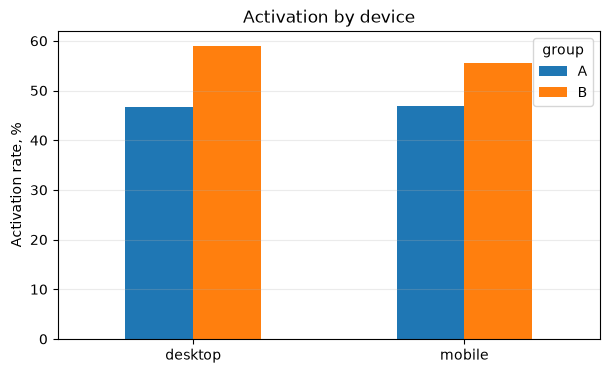

In [12]:
segment = (
    df.groupby(['device', 'group'])['activated']
    .mean()
    .unstack('group')
)

display((segment * 100).round(1))

ax = (segment * 100).plot(kind='bar', figsize=(7, 4))
ax.set_ylabel('Activation rate, %')
ax.set_title('Activation by device')
ax.set_xlabel('')
ax.grid(axis='y', alpha=0.25)
plt.xticks(rotation=0)
plt.show()


Направление эффекта B > A сохраняется и на desktop, и на mobile. Этот анализ считаем поддерживающим: отдельную статистическую мощность для каждого сегмента заранее не планировали.

## 9. Итоговый продуктовый вывод

**Рекомендация: раскатить новый onboarding (B).**

Основные причины:

1. Primary metric — Activation Rate — выросла статистически значимо.
2. Прирост не сосредоточен только в одном устройстве.
3. Guardrail по обращениям в поддержку не ухудшился.
4. Пользователи быстрее подключают магазин.
5. D7 retention не показал статистически значимого изменения, поэтому нельзя утверждать, что новый onboarding улучшает долгосрочное удержание.

### Что мониторить после rollout

- Activation Rate;
- D7/D30 Retention;
- Support Ticket Rate;
- ошибки подключения API;
- время до первого отчёта.